# Analyzing Model Outputs By Parameter - Logit

To assess the model with the Logit analysis, we ran a large parameter sweep with 5 runs for each combination of the following parameters:

* Cost functions: cost_funcs = ["raam"]
* Transportation Options: noveh = ['onlycars']
* Time Steps: timesteps = [10, 15, 20]
* Rationality: topK = [1, 2, 3, 4, 5]
* Ratio of People to Agents: numAgents = [1000, 100, 10]

In [1]:
from collections import Counter
import itertools
import json
import geopandas as gpd
from glob import glob
from libpysal.weights import Queen
from esda.moran import Moran
import math
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import matplotlib.cm as cm
import numpy as np
import pandas as pd
from scipy.stats import kendalltau
import seaborn as sns
import os

/home/dal384425/Documents/GitHubRepos/AgentAccess/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Below just lists the varous accessibility fields calculated by the Pysal `access` package and a dictionary that maps the column name to a more "human readable" version of the name.

In [2]:
acc_cols = ['gravity_BEDS', '2sfca_30_BEDS', '2sfca_60_BEDS', 'e2sfca_30_BEDS', 'e2sfca_60_BEDS',
            'g2sfca10_BEDS', 'g2sfca20_BEDS', '3sfca_BEDS', 'raam30_BEDS', 'raam60_BEDS']
acc_titles = {
    'gravity_BEDS': "Gravity",
    '2sfca_30_BEDS': "2SFCA (30min)",
    '2sfca_60_BEDS': "2SFCA (60min)",
    'e2sfca_30_BEDS': "E2SFCA (30min)",
    'e2sfca_60_BEDS': "E2SFCA (60 min)",
    'g2sfca10_BEDS': r"G2SFCA ($\sigma$=10)",
    'g2sfca20_BEDS': r"G2SFCA ($\sigma$=20)",
    '3sfca_BEDS': "3SFCA",
    'raam30_BEDS': r"RAAM ($\tau$=30)",
    'raam60_BEDS': r"RAAM ($\tau$=60)"
}

The next code block allows us to compare a given spatial accessibility method to our model outputs.

* `acc_corr` is the traditional accessibility method column we will calculate correlations against.
* `Cost_2` is the AgentAccess model output we will use. we have 2, 3, and 4 corresponding to the average of the last 1/2, 1/3, and 1/4 timesteps of the model.

In [3]:
acc_corr = "raam30_BEDS"
# acc_corr = "gravity_BEDS"
res_col = "Cost_2"

Loading the hospital data to aid in analysis.

In [4]:
# load the hospitals
hos = gpd.read_file("../data/hospitals/ContinentalHospitals.shp")
hos = hos[(hos["STATE"] == "IL") & (hos["COUNTY"] == "COOK")]
hos = hos[hos["BEDS"] >= 0]
hos = hos.to_crs("EPSG:4326")
print(len(hos), sum(hos["BEDS"]))
hos.head()

66 18259


,OBJECTID,ID,NAME,ADDRESS,CITY,STATE,ZIP,ZIP4,TELEPHONE,TYPE,...,WEBSITE,STATE_ID,ALT_NAME,ST_FIPS,OWNER,TTL_STAFF,BEDS,TRAUMA,HELIPAD,geometry
507,1513,0003460644,UHS HARTGROVE HOSPITAL,5730 WEST ROOSEVELT ROAD,CHICAGO,IL,60644,NOT AVAILABLE,(773) 413-1700,PSYCHIATRIC,...,http://www.hartgrovehospital.com,0005454,NOT AVAILABLE,17,PROPRIETARY,-999,128,NOT AVAILABLE,N,POINT (-87.76746 41.86633)
508,1514,0001860612,JESSE BROWN VA MEDICAL CENTER - VA CHICAGO HEA...,820 S DAMEN STREET,CHICAGO,IL,60612,NOT AVAILABLE,(312) 569-8387,MILITARY,...,http://www.chicago.va.gov/,14003F,NOT AVAILABLE,17,GOVERNMENT - FEDERAL,-999,240,NOT AVAILABLE,N,POINT (-87.67704 41.87074)
509,1515,0003160463,PALOS COMMUNITY HOSPITAL,12251 SOUTH 80TH AVENUE,PALOS HEIGHTS,IL,60464,NOT AVAILABLE,(708) 923-4000,GENERAL ACUTE CARE,...,http://www.paloscommunityhospital.org,140062,NOT AVAILABLE,17,NON-PROFIT,-999,377,NOT AVAILABLE,Y,POINT (-87.81344 41.66921)
510,1516,0003660628,ROSELAND COMMUNITY HOSPITAL,45 W 111TH STREET,CHICAGO,IL,60628,NOT AVAILABLE,(773) 995-3000,GENERAL ACUTE CARE,...,http://www.roselandhospital.org,140068,NOT AVAILABLE,17,NON-PROFIT,-999,115,NOT AVAILABLE,N,POINT (-87.62536 41.69223)
511,1517,0002360302,WEST SUBURBAN MEDICAL CENTER,3 ERIE COURT,OAK PARK,IL,60302,NOT AVAILABLE,(708) 383-6200,GENERAL ACUTE CARE,...,http://www.westsuburbanmc.com/Home.aspx,140049,NOT AVAILABLE,17,PROPRIETARY,-999,172,NOT AVAILABLE,N,POINT (-87.77618 41.8914)


Load our analysis of accessibility to hospital beds in Cook County.

In [5]:
acc = gpd.read_file("../data/accessibility/CookHospitals.gpkg")
acc = acc.set_index("FIPS")
cols = list(acc.columns)
cols.remove('geometry')
# acc = normalize_columns(acc, cols)
# drop rows with nan values
acc = acc.dropna(subset=[acc_corr])
print(len(acc))
acc.head()

1315


,gravity_BEDS,2sfca_30_BEDS,2sfca_60_BEDS,e2sfca_30_BEDS,e2sfca_60_BEDS,g2sfca10_BEDS,g2sfca20_BEDS,3sfca_BEDS,raam30_BEDS,raam60_BEDS,geometry
FIPS,,,,,,,,,,,
17031010100,65335.763181,0.003517,0.002790,0.004005,0.002484,0.003534,0.002699,0.005337,1.353203,1.151754,"POLYGON ((-87.6772 42.02294, -87.67007 42.0229..."
17031010201,84737.705650,0.003517,0.003022,0.004239,0.002714,0.003749,0.002867,0.005148,1.278645,1.115558,"POLYGON ((-87.68465 42.01949, -87.68045 42.019..."
17031010202,64835.519563,0.003517,0.002956,0.004371,0.002645,0.003102,0.002820,0.005539,1.375311,1.173011,"POLYGON ((-87.67685 42.01941, -87.67339 42.019..."
17031010300,61203.919275,0.003517,0.002931,0.004462,0.002648,0.002880,0.002814,0.005940,1.428868,1.187285,"POLYGON ((-87.67133 42.01937, -87.6695 42.0193..."
17031010400,68054.999255,0.003314,0.003050,0.002969,0.003023,0.002651,0.003120,0.004095,1.375371,1.126623,"POLYGON ((-87.66345 42.01283, -87.66133 42.012..."


## AgentAccess Experimental Results

For each set of parameters, we ran the model 5 times resulting in ($2\cdot 2 \cdot 5 \cdot 5 \cdot 4 \cdot 5$) 2000 runs of the model.

The next few lines will collect all of the experiment outputs, in two categories: "NoVeh" meaning models that included the Census "No Vehicles" data and "Only Cars" which assumes everyone is using the driving-time data.

In [6]:
experiment_paths_logit = glob("../outputs/Logit/*")

Here we spell out all of the parameters we tested which is useful for iterating and sanity checking.

In [7]:
# params tested
cost_funcs = ["raam"]
noveh = ['onlycars']
timesteps = [10, 15, 20]
topK = [1, 2, 3, 4, 5]
numAgents = [1000, 100, 10]

Below is a quick sanity check that ensures we have the appropriate number of results for each parameter choice.

In [8]:
# quick sanity check
cf_counter, ts_counter, tk_counter, na_counter = Counter(), Counter(), Counter(), Counter()
for path in experiment_paths_logit:
    # print(path)
    # load the parameter json
    param_path = os.path.join(path, "parameters.json")
    param_file = open(param_path)
    params = json.load(param_file)
    cf, ts, tk, na = params["cost_function"], params["time_steps"], params["top_k"], params["pop_per_agent"]
    # if cf == "gravity" and ts == 25 and tk == 3 and na == 1:
    #     print(path)
#     print(cf, ts, tk, na)
    cf_counter[cf] +=1
    ts_counter[ts] +=1
    tk_counter[tk] +=1
    na_counter[na] +=1
# you should see even numbers for all parameter options
cf_counter, ts_counter, tk_counter, na_counter

(Counter({'raam': 225}),
 Counter({15: 75, 10: 75, 20: 75}),
 Counter({5: 45, 1: 45, 4: 45, 2: 45, 3: 45}),
 Counter({10: 75, 1000: 75, 100: 75}))

The function below calculates the Kendall's $\tau$ correlation between each model output and our spatial accessibility measure, collecting it all into a dictionary that maps the parameters to a list of correlations.

In [9]:
def calculate_corrs(acc_corr, res_col):
    experiment_corr = dict()
    _negate_corr = not ("raam" in acc_corr)
    for path in experiment_paths_logit :
        # load the parameter json
        param_path = os.path.join(path, "parameters.json")
        param_file = open(param_path)
        params = json.load(param_file)
        cf, ts, tk, na = params["cost_function"], params["time_steps"], params["top_k"], params["pop_per_agent"]
        # load the data
        results = pd.read_csv(os.path.join(path, "spatial_units.csv"), index_col="GEOID")
        results.index = results.index.map(str)
        # join with accessibility data on GEOID
        # join the last time step's cost
        merged = pd.merge(acc[[acc_corr]], results[[res_col]], left_index=True, right_index=True)
    #     print(len(merged))
        corr_res = kendalltau(merged[acc_corr], merged[res_col])
        if _negate_corr:
            _correlation = -corr_res.correlation
        else:
            _correlation = corr_res.correlation  # negate from access to cost
        try:
            experiment_corr["onlycars", cf, ts, tk, na].append(_correlation)
        except:
            experiment_corr["onlycars", cf, ts, tk, na] = [_correlation]
    return experiment_corr

In [10]:
experiment_corr = calculate_corrs(acc_corr, res_col)
experiment_corr

{('onlycars', 'raam', 15, 5, 10): [np.float64(0.8213712767120418),
  np.float64(0.8222185440434049),
  np.float64(0.8222833623091922),
  np.float64(0.8214060007829993),
  np.float64(0.8217347219880636)],
 ('onlycars', 'raam', 10, 1, 1000): [np.float64(0.870898573706455),
  np.float64(0.870898573706455),
  np.float64(0.870898573706455),
  np.float64(0.870898573706455),
  np.float64(0.870898573706455)],
 ('onlycars', 'raam', 20, 4, 1000): [np.float64(0.8241630920170252),
  np.float64(0.8309805846150152),
  np.float64(0.828200344000351),
  np.float64(0.8274109501205837),
  np.float64(0.8285661042144368)],
 ('onlycars', 'raam', 20, 2, 1000): [np.float64(0.8965187961402098),
  np.float64(0.8937385555255456),
  np.float64(0.891518529922329),
  np.float64(0.8935209513475452),
  np.float64(0.8956831034991659)],
 ('onlycars', 'raam', 15, 2, 100): [np.float64(0.9010421851169408),
  np.float64(0.9004889149196845),
  np.float64(0.9035631526684557),
  np.float64(0.8999518492888752),
  np.float64(0.

Below is a simple function to calculate the minimum and maximum correlations to help set the y-axis limits for visualizations.

In [11]:
def get_ylims(ecorr):
    corrs = {'raam': []}
    for k, v in ecorr.items():
        corrs[k[1]].extend(v)
    _min = math.floor(min(corrs['raam'])*10)/10
    _max = math.ceil(max(corrs['raam'])*10)/10
    return(_min, _max)

In [12]:
print(get_ylims(experiment_corr))

(0.7, 1.0)


The function below uses our correlation data to create boxplots of the correlations between the spatial acccessibility method and our AgentAccess outputs, broken down by parameter:

In [13]:
def parameter_boxplots(experiment_corr, save_path):
    fig, axes = plt.subplots(2, 3, figsize=(12, 6))
    ylims = get_ylims(experiment_corr)
    colors = [
        ["#6267f5", "#6cf562"],
        ["#f56462", "#f5a462"]
    ]

    fsize = 20
    for j, nv in enumerate(noveh):
        # get the ax for numAgents
        ax = axes[j, 0]
        parameters = numAgents
        oparameters = (timesteps, topK)
        vals = dict()
        for p in parameters:
            vals[p] = list()
            for a, b in itertools.product(*oparameters):
                vals[p].extend(experiment_corr[nv, cf, a, b, p])
        x_labels = [str(x) for x in parameters]
        data = [vals[p] for p in parameters]
        ax.boxplot(data, tick_labels=x_labels)
        # ax.set_title(f"{cf}, {nv}")
        ax.set_ylim(*ylims)

        # get the ax for topk
        ax = axes[j, 1]
        parameters = topK
        oparameters = (timesteps, numAgents)
        vals = dict()
        for p in parameters:
            vals[p] = list()
            for a, b in itertools.product(*oparameters):
                vals[p].extend(experiment_corr[nv, cf, a, p, b])
        x_labels = [str(x) for x in parameters]
        data = [vals[p] for p in parameters]
        ax.boxplot(data, tick_labels=x_labels)
        ax.set_yticklabels([])
        # ax.set_title(f"{cf}-{nv}")
        ax.set_ylim(*ylims)

        
        # get the ax for timesteps
        ax = axes[j, 2]
        parameters = timesteps
        oparameters = (topK, numAgents)
        vals = dict()
        for p in parameters:
            vals[p] = list()
            for a, b in itertools.product(*oparameters):
                vals[p].extend(experiment_corr[nv, cf, p, a, b])
        x_labels = [str(x) for x in parameters]
        data = [vals[p] for p in parameters]
        ax.boxplot(data, tick_labels=x_labels)
        ax.set_ylim(*ylims)
        ax.set_yticklabels([])

    for ax in axes.flatten():
        ax.tick_params(axis='both', which='major', labelsize=fsize-4)
        ax.grid('on')

    clabels = ["PopPerAgent", "topK", "Time Steps"]
    for ax, clab in zip(axes[0], clabels):
        ax.set_title(clab, fontsize=fsize)
    rlabels = ["RAAM, Cars", "RAAM, NoVeh", "Gravity, Cars", "Gravity, NoVeh"]
    for ax, lab in zip(axes[:, 0], rlabels):
        ax.set_ylabel(lab, fontsize=fsize)

    spacer = "     "
    fig.supylabel(f"Correlations between Model Results and Traditional {acc_titles[acc_corr]} Method", fontsize=20)
    # fig.supxlabel(f"Distribution of Correlations by Parameter", fontsize=24)

    plt.subplots_adjust(wspace=0, hspace=0)
    fig.tight_layout()
    plt.savefig(save_path, dpi=400)
    plt.show()

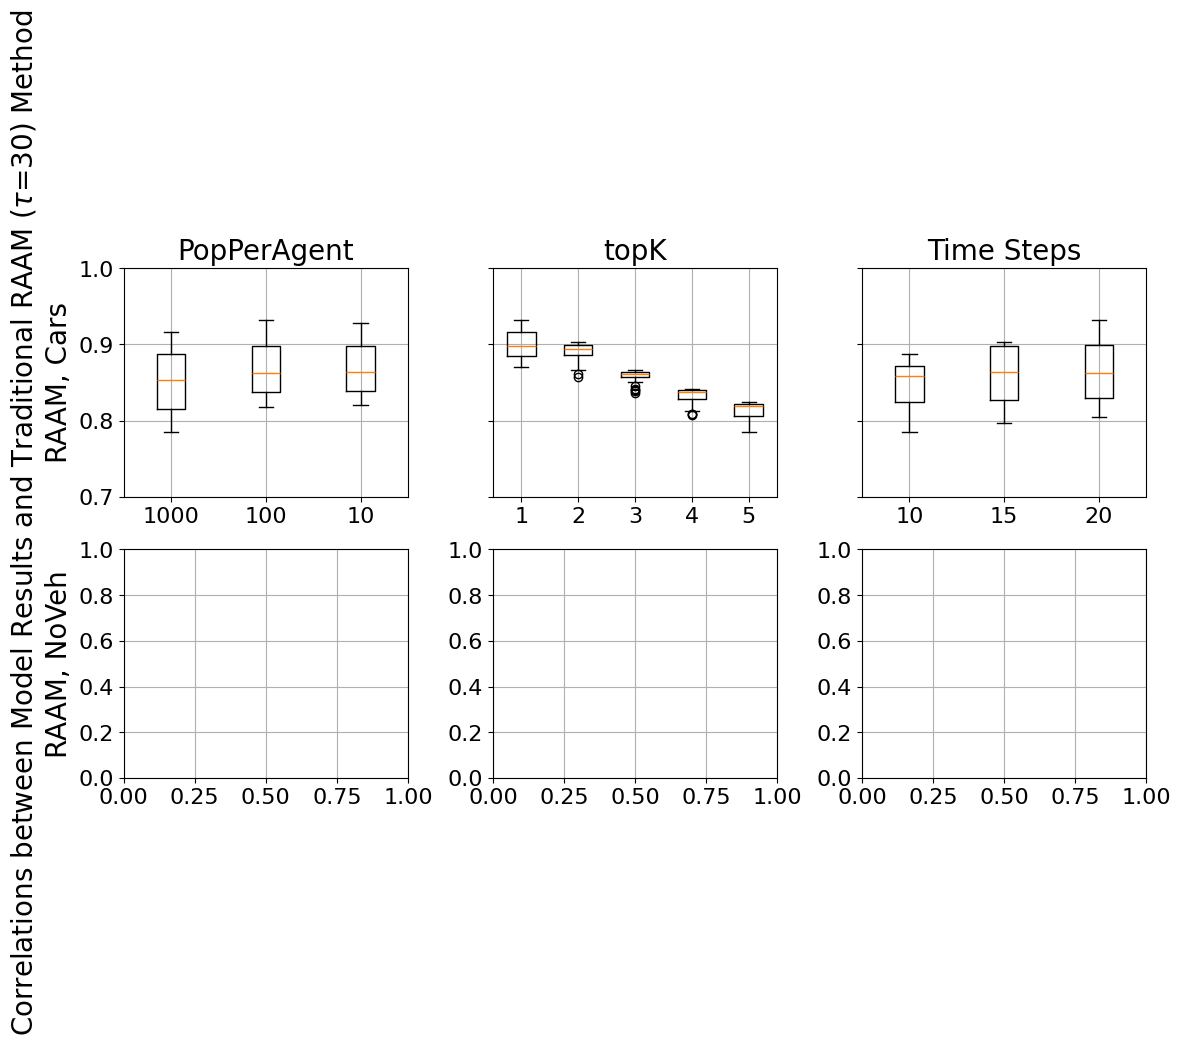

In [14]:
# for acc_col in cols:
# for acc_col in ['raam60_BEDS']:
#     print(acc_col)
#     experiment_corr = calculate_corrs(acc_col, res_col)
parameter_boxplots(experiment_corr,f"../figs/CorrelationsByParameter{acc_corr}-Logit.png")

## Mapping Results using "RAAM" Cost Function

For a completely fair comparison, we will also ignore the "NoVeh" results. We will start by creating a copy of our spatial accessibility outputs and then collecting the results for each spatial unit and model run:

In [15]:
cost_dict = {x: [] for x in acc.index}
for path in experiment_paths_logit:
    # load the parameter json
    param_path = os.path.join(path, "parameters.json")
    param_file = open(param_path)
    params = json.load(param_file)
    cf, ts, tk, na = params["cost_function"], params["time_steps"], params["top_k"], params["pop_per_agent"]
    if cf == "raam":
        # load the data
        results = pd.read_csv(os.path.join(path, "spatial_units.csv"), index_col="GEOID")
        results.index = results.index.map(str)
        for index, row in results.iterrows():
            try:
                cost_dict[index].append(row[res_col])
            except:
                cost_dict[index] = []
                cost_dict[index].append(row[res_col])

In [16]:
# cost_dict

In [17]:
avg_costs = {key: np.mean(val) for key, val in cost_dict.items()}  # calculate mean by spatial unit

In [18]:
avg_cost_df = pd.DataFrame.from_dict(avg_costs, orient='index', columns=['AgentAccess'])
avg_cost_df.head()

,AgentAccess
17031010100,1.368274
17031010201,1.329363
17031010202,1.397724
17031010300,1.421937
17031010400,1.450562


Join our AccessAccess average cost dictionary to a copy of our accessibility outputs dataframe:

In [19]:
merged = acc.copy(deep=True).merge(avg_cost_df, left_index=True, right_index=True)
merged.head()

,gravity_BEDS,2sfca_30_BEDS,2sfca_60_BEDS,e2sfca_30_BEDS,e2sfca_60_BEDS,g2sfca10_BEDS,g2sfca20_BEDS,3sfca_BEDS,raam30_BEDS,raam60_BEDS,geometry,AgentAccess
FIPS,,,,,,,,,,,,
17031010100,65335.763181,0.003517,0.002790,0.004005,0.002484,0.003534,0.002699,0.005337,1.353203,1.151754,"POLYGON ((-87.6772 42.02294, -87.67007 42.0229...",1.368274
17031010201,84737.705650,0.003517,0.003022,0.004239,0.002714,0.003749,0.002867,0.005148,1.278645,1.115558,"POLYGON ((-87.68465 42.01949, -87.68045 42.019...",1.329363
17031010202,64835.519563,0.003517,0.002956,0.004371,0.002645,0.003102,0.002820,0.005539,1.375311,1.173011,"POLYGON ((-87.67685 42.01941, -87.67339 42.019...",1.397724
17031010300,61203.919275,0.003517,0.002931,0.004462,0.002648,0.002880,0.002814,0.005940,1.428868,1.187285,"POLYGON ((-87.67133 42.01937, -87.6695 42.0193...",1.421937
17031010400,68054.999255,0.003314,0.003050,0.002969,0.003023,0.002651,0.003120,0.004095,1.375371,1.126623,"POLYGON ((-87.66345 42.01283, -87.66133 42.012...",1.450562


We can now calculate a correlation matrix between our average model outputs and other spatial accessibility methods:

<Axes: >

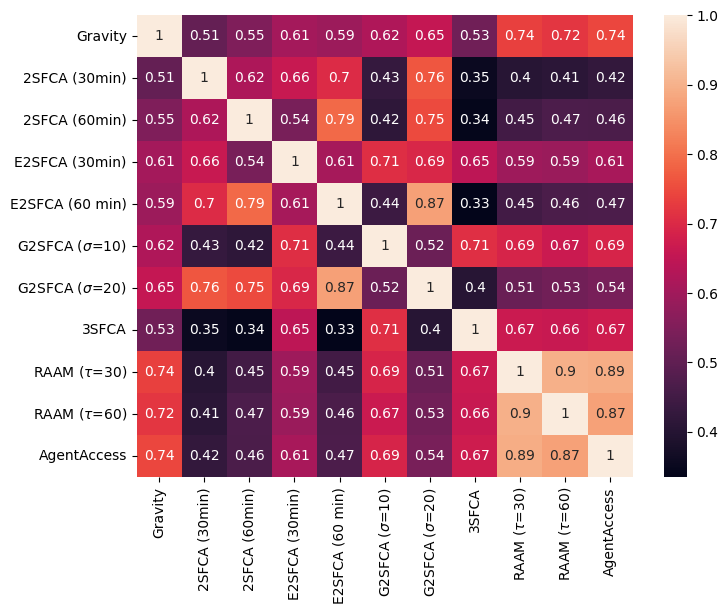

In [20]:
tmp = merged.drop(columns=["geometry"])
to_negate = ['raam30_BEDS', 'raam60_BEDS', 'AgentAccess']
for col in to_negate:
    tmp[col] = - tmp[col]
tmp = tmp.rename(columns=acc_titles)
corr = tmp.corr(method='kendall')
fig, ax = plt.subplots(figsize=(8, 6))  
sns.heatmap(corr, annot=True, ax=ax)

Let's plot the distribution of average costs using boxplots:

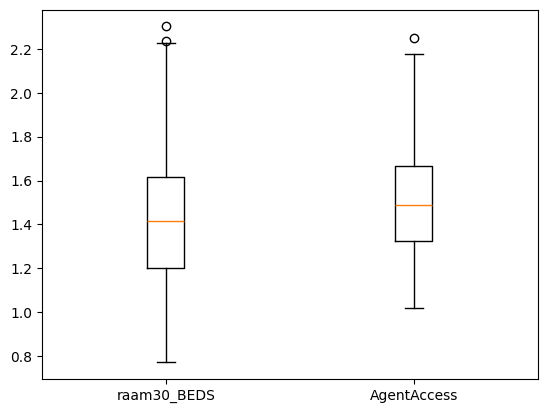

In [21]:
plt.boxplot([merged[acc_corr], merged["AgentAccess"]], tick_labels=[acc_corr, "AgentAccess"])
plt.show()

We can also map the same data:

<Axes: >

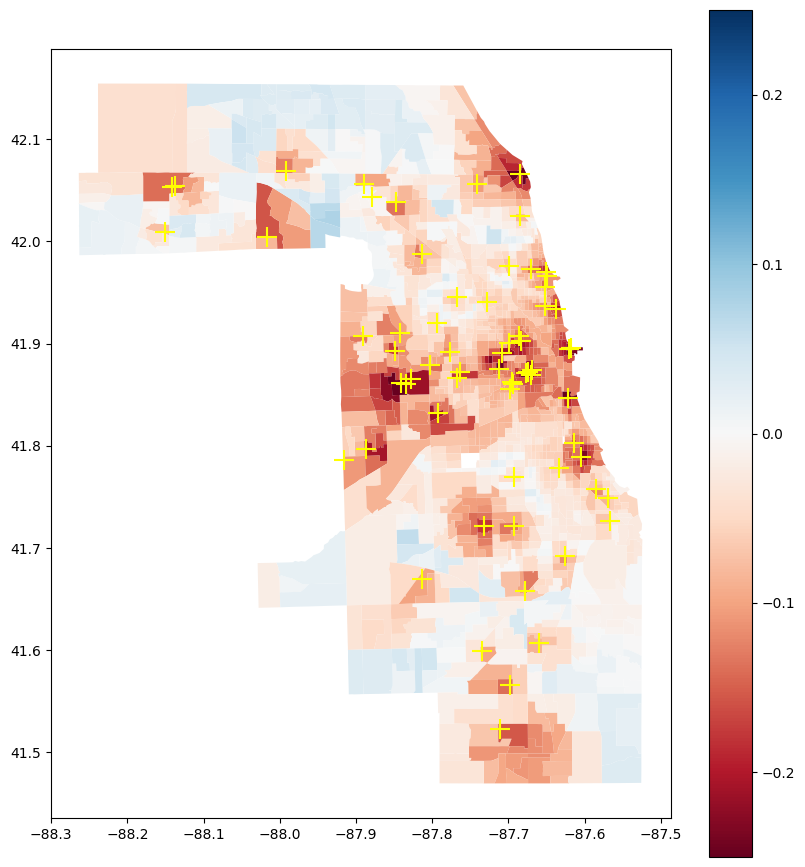

In [22]:
merged["diff"] = (merged[acc_corr] - merged['AgentAccess']) / ((merged[acc_corr] + merged['AgentAccess']) / 2.0)
ax = merged.plot(column='diff', figsize=(10, 11), legend=True, cmap="RdBu", vmin=-.25, vmax=.25)
hos.plot(ax=ax, color='yellow', marker='+', markersize=200)
# merged.head()

# Mean costs by top k

,gravity_BEDS,2sfca_30_BEDS,2sfca_60_BEDS,e2sfca_30_BEDS,e2sfca_60_BEDS,g2sfca10_BEDS,g2sfca20_BEDS,3sfca_BEDS,raam30_BEDS,raam60_BEDS,geometry
FIPS,,,,,,,,,,,
17031010100,65335.763181,0.003517,0.002790,0.004005,0.002484,0.003534,0.002699,0.005337,1.353203,1.151754,"POLYGON ((-87.6772 42.02294, -87.67007 42.0229..."
17031010201,84737.705650,0.003517,0.003022,0.004239,0.002714,0.003749,0.002867,0.005148,1.278645,1.115558,"POLYGON ((-87.68465 42.01949, -87.68045 42.019..."
17031010202,64835.519563,0.003517,0.002956,0.004371,0.002645,0.003102,0.002820,0.005539,1.375311,1.173011,"POLYGON ((-87.67685 42.01941, -87.67339 42.019..."
17031010300,61203.919275,0.003517,0.002931,0.004462,0.002648,0.002880,0.002814,0.005940,1.428868,1.187285,"POLYGON ((-87.67133 42.01937, -87.6695 42.0193..."
17031010400,68054.999255,0.003314,0.003050,0.002969,0.003023,0.002651,0.003120,0.004095,1.375371,1.126623,"POLYGON ((-87.66345 42.01283, -87.66133 42.012..."


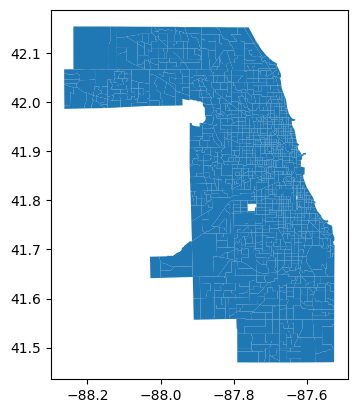

In [23]:
mean_costs_byk = acc.copy(deep=True)
mean_costs_byk.plot()
mean_costs_byk.head()

In [24]:
cost_dict = {x: dict() for x in acc.index}
for path in experiment_paths_logit :
    # load the parameter json
    param_path = os.path.join(path, "parameters.json")
    param_file = open(param_path)
    params = json.load(param_file)
    cf, ts, tk, na = params["cost_function"], params["time_steps"], params["top_k"], params["pop_per_agent"]
    if cf == "raam":
        # load the data
        results = pd.read_csv(os.path.join(path, "spatial_units.csv"), index_col="GEOID")
        results.index = results.index.map(str)
        for index, row in results.iterrows():
            try:
                cost_dict[index][tk].append(row[res_col])
            except:
                try:
                    cost_dict[index][tk] = []
                except:
                    cost_dict[index] = dict()
                    cost_dict[index][tk] = []
                cost_dict[index][tk].append(row[res_col])
                    

In [25]:
list(cost_dict.items())[:5]  # get a preview

[('17031010100',
  {5: [np.float64(1.466503648496854),
    np.float64(1.4275754607338396),
    np.float64(1.4816782797737011),
    np.float64(1.4619022030479545),
    np.float64(1.4523533970515972),
    np.float64(1.497255021405094),
    np.float64(1.4402518795589394),
    np.float64(1.4164716922788407),
    np.float64(1.4264799104927082),
    np.float64(1.4530163940448246),
    np.float64(1.476121120802709),
    np.float64(1.457101792400954),
    np.float64(1.471706499724467),
    np.float64(1.472408692387684),
    np.float64(1.3863216509099856),
    np.float64(1.4824465829425084),
    np.float64(1.45608785695828),
    np.float64(1.4577650979942631),
    np.float64(1.4534028505935248),
    np.float64(1.418778721921191),
    np.float64(1.4780148377539135),
    np.float64(1.463621888381811),
    np.float64(1.455508108033562),
    np.float64(1.4541554853824838),
    np.float64(1.4677609406205128),
    np.float64(1.4607136873864306),
    np.float64(1.4547792929138068),
    np.float64(1.48

In [26]:
# list comprehensions can become very dumb
# for each spatial unit (key) we want average the list of results (val) indexed by the topK value (i)
avg_costs_byk = {key: [np.mean(val[i]) for i in topK] for key, val in cost_dict.items()}

In [27]:
list(avg_costs_byk.items())[:5]  # get a preview

[('17031010100',
  [np.float64(1.2642136152139747),
   np.float64(1.3053843115105397),
   np.float64(1.384757199025861),
   np.float64(1.4282896024549703),
   np.float64(1.4587255209620515)]),
 ('17031010201',
  [np.float64(1.203088208493714),
   np.float64(1.279933420261569),
   np.float64(1.3558048416812862),
   np.float64(1.3871867767383057),
   np.float64(1.4208031523068125)]),
 ('17031010202',
  [np.float64(1.2996662868331248),
   np.float64(1.3551627399322905),
   np.float64(1.4182584182806162),
   np.float64(1.4433361947324221),
   np.float64(1.4721986447739965)]),
 ('17031010300',
  [np.float64(1.3426833206926176),
   np.float64(1.3844362366972638),
   np.float64(1.4339016591855536),
   np.float64(1.458037269500814),
   np.float64(1.4906274475235781)]),
 ('17031010400',
  [np.float64(1.3502068484401715),
   np.float64(1.4505565822356692),
   np.float64(1.4783038241716469),
   np.float64(1.4792643686633584),
   np.float64(1.4944767250057973)])]

In [28]:
avg_cost_byk_df = pd.DataFrame.from_dict(avg_costs_byk, orient='index', columns=[f'topK={k}' for k in topK])
avg_cost_byk_df.head()

,topK=1,topK=2,topK=3,topK=4,topK=5
17031010100,1.264214,1.305384,1.384757,1.428290,1.458726
17031010201,1.203088,1.279933,1.355805,1.387187,1.420803
17031010202,1.299666,1.355163,1.418258,1.443336,1.472199
17031010300,1.342683,1.384436,1.433902,1.458037,1.490627
17031010400,1.350207,1.450557,1.478304,1.479264,1.494477


In [29]:
merged_byk = acc.merge(avg_cost_byk_df, left_index=True, right_index=True)
merged_byk.head()

,gravity_BEDS,2sfca_30_BEDS,2sfca_60_BEDS,e2sfca_30_BEDS,e2sfca_60_BEDS,g2sfca10_BEDS,g2sfca20_BEDS,3sfca_BEDS,raam30_BEDS,raam60_BEDS,geometry,topK=1,topK=2,topK=3,topK=4,topK=5
FIPS,,,,,,,,,,,,,,,,
17031010100,65335.763181,0.003517,0.002790,0.004005,0.002484,0.003534,0.002699,0.005337,1.353203,1.151754,"POLYGON ((-87.6772 42.02294, -87.67007 42.0229...",1.264214,1.305384,1.384757,1.428290,1.458726
17031010201,84737.705650,0.003517,0.003022,0.004239,0.002714,0.003749,0.002867,0.005148,1.278645,1.115558,"POLYGON ((-87.68465 42.01949, -87.68045 42.019...",1.203088,1.279933,1.355805,1.387187,1.420803
17031010202,64835.519563,0.003517,0.002956,0.004371,0.002645,0.003102,0.002820,0.005539,1.375311,1.173011,"POLYGON ((-87.67685 42.01941, -87.67339 42.019...",1.299666,1.355163,1.418258,1.443336,1.472199
17031010300,61203.919275,0.003517,0.002931,0.004462,0.002648,0.002880,0.002814,0.005940,1.428868,1.187285,"POLYGON ((-87.67133 42.01937, -87.6695 42.0193...",1.342683,1.384436,1.433902,1.458037,1.490627
17031010400,68054.999255,0.003314,0.003050,0.002969,0.003023,0.002651,0.003120,0.004095,1.375371,1.126623,"POLYGON ((-87.66345 42.01283, -87.66133 42.012...",1.350207,1.450557,1.478304,1.479264,1.494477


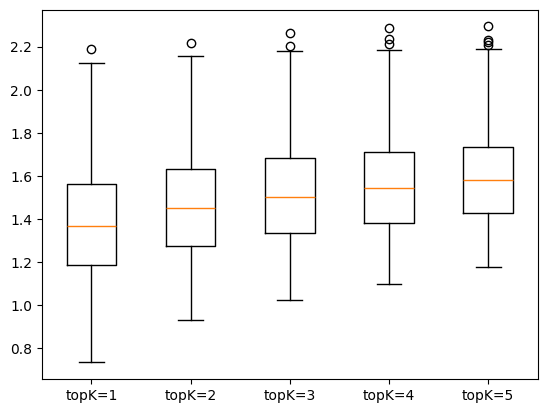

In [30]:
data, labels = [], []
for k in topK:
    data.append(merged_byk[f'topK={k}'])
    labels.append(f'topK={k}')
plt.boxplot(data, tick_labels=labels)
plt.show()

/tmp/ipykernel_1935603/312521722.py:9: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  w = Queen.from_dataframe(merged_byk)


1: Moran's I: 0.8875849580868362, p-value: 0.001
2: Moran's I: 0.7245071512295588, p-value: 0.001
3: Moran's I: 0.7580106574785469, p-value: 0.001
4: Moran's I: 0.7872333586851058, p-value: 0.001
5: Moran's I: 0.8126108783111929, p-value: 0.001


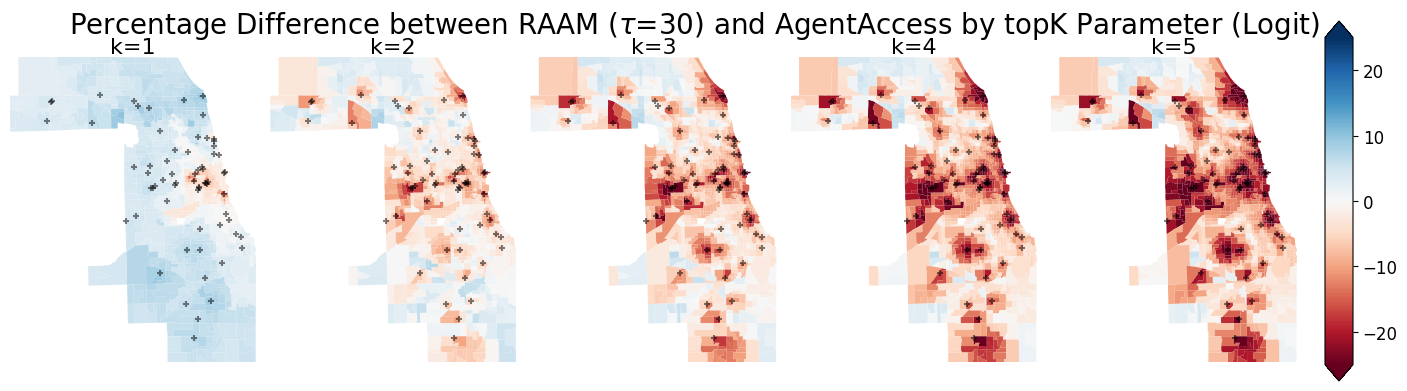

In [31]:
fontsize = 16
mycmap="RdBu"
hosmarkersize = 25
vmin, vmax = -25, 25

fig, axes = plt.subplots(1, 5, figsize=(14, 4))
fig.subplots_adjust(wspace=0, hspace=.1)

w = Queen.from_dataframe(merged_byk)
w.transform = 'R'

for ind, (k, ax) in enumerate(zip(topK, axes.flatten())):
    merged_byk[f"diff_{k}"] = 100 *(merged_byk[acc_corr] - merged_byk[f'topK={k}']) / ((merged_byk[acc_corr] + merged_byk[f'topK={k}']) / 2.0)
    ax.set_title(f"k={k}", fontsize=fontsize, pad=0)
    merged_byk.plot(ax=ax, column=f"diff_{k}", cmap=mycmap, vmin=vmin, vmax=vmax)
    moran = Moran(merged_byk[f"diff_{k}"], w)
    print(f"{k}: Moran's I: {moran.I}, p-value: {moran.p_sim}")
    ax.axis('off')
    ax.margins(0)
    hos.plot(ax=ax, alpha=.5, color='black', marker='+', markersize=hosmarkersize)
plt.tight_layout()


normalizer = Normalize(vmin, vmax)
im = cm.ScalarMappable(cmap=mycmap, norm=normalizer)
fig.subplots_adjust(right=0.93)
# recttuple (left, bottom, width, height)
cbar_ax = fig.add_axes([0.95, 0.05, 0.02, 0.9])

cbar_ax.tick_params(labelsize=fontsize-4)
fig.colorbar(im, cax=cbar_ax, extend='both')

fig.subplots_adjust(top=0.92)
fig.suptitle(f"Percentage Difference between {acc_titles[acc_corr]} and AgentAccess by topK Parameter (Logit)", fontsize=fontsize+4)

# plt.tight_layout()
plt.savefig(f"../figs/ComparisonByTopK-{acc_corr}-Logit.png", dpi=400, bbox_inches='tight', pad_inches=0)
plt.show()

# Mean costs by Number of Agents

,gravity_BEDS,2sfca_30_BEDS,2sfca_60_BEDS,e2sfca_30_BEDS,e2sfca_60_BEDS,g2sfca10_BEDS,g2sfca20_BEDS,3sfca_BEDS,raam30_BEDS,raam60_BEDS,geometry
FIPS,,,,,,,,,,,
17031010100,65335.763181,0.003517,0.002790,0.004005,0.002484,0.003534,0.002699,0.005337,1.353203,1.151754,"POLYGON ((-87.6772 42.02294, -87.67007 42.0229..."
17031010201,84737.705650,0.003517,0.003022,0.004239,0.002714,0.003749,0.002867,0.005148,1.278645,1.115558,"POLYGON ((-87.68465 42.01949, -87.68045 42.019..."
17031010202,64835.519563,0.003517,0.002956,0.004371,0.002645,0.003102,0.002820,0.005539,1.375311,1.173011,"POLYGON ((-87.67685 42.01941, -87.67339 42.019..."
17031010300,61203.919275,0.003517,0.002931,0.004462,0.002648,0.002880,0.002814,0.005940,1.428868,1.187285,"POLYGON ((-87.67133 42.01937, -87.6695 42.0193..."
17031010400,68054.999255,0.003314,0.003050,0.002969,0.003023,0.002651,0.003120,0.004095,1.375371,1.126623,"POLYGON ((-87.66345 42.01283, -87.66133 42.012..."


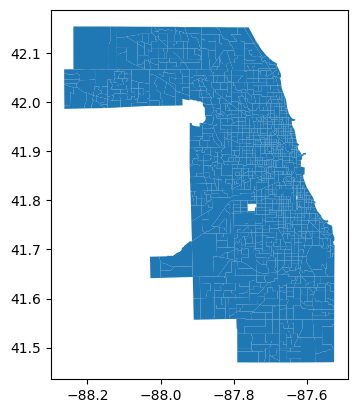

In [32]:
mean_costs_nagents = acc.copy(deep=True)
mean_costs_nagents.plot()
mean_costs_nagents.head()

In [33]:
cost_dict = {x: dict() for x in acc.index}
for path in experiment_paths_logit:
    # load the parameter json
    param_path = os.path.join(path, "parameters.json")
    param_file = open(param_path)
    params = json.load(param_file)
    cf, ts, tk, na = params["cost_function"], params["time_steps"], params["top_k"], params["pop_per_agent"]
    if cf == "raam":
        # load the data
        results = pd.read_csv(os.path.join(path, "spatial_units.csv"), index_col="GEOID")
        results.index = results.index.map(str)
        for index, row in results.iterrows():
            try:
                cost_dict[index][na].append(row[res_col])
            except:
                try:
                    cost_dict[index][na] = []
                except:
                    cost_dict[index] = dict()
                    cost_dict[index][na] = []
                cost_dict[index][na].append(row[res_col])
                    

In [34]:
list(cost_dict.items())[:5]  # get a preview

[('17031010100',
  {10: [np.float64(1.466503648496854),
    np.float64(1.439006648028457),
    np.float64(1.4081896543933674),
    np.float64(1.2847764607633667),
    np.float64(1.3413029758777095),
    np.float64(1.4406975102471815),
    np.float64(1.3388548236879383),
    np.float64(1.312303600618439),
    np.float64(1.4115247769719246),
    np.float64(1.323472938265695),
    np.float64(1.4307733916872765),
    np.float64(1.312303600618439),
    np.float64(1.4145937957305743),
    np.float64(1.2847764607633667),
    np.float64(1.3414589574366207),
    np.float64(1.1943850685759905),
    np.float64(1.471706499724467),
    np.float64(1.361673226282934),
    np.float64(1.472408692387684),
    np.float64(1.4382171146419858),
    np.float64(1.4418516831969952),
    np.float64(1.4085096994183086),
    np.float64(1.36565098451183),
    np.float64(1.1943850685759905),
    np.float64(1.403005150380083),
    np.float64(1.3209115414431911),
    np.float64(1.4337630567934718),
    np.float64(1.4

In [35]:
# list comprehensions can become very dumb
# for each spatial unit (key) we want average the list of results (val) indexed by the numAgents value (i)
avg_costs_popPerAgent = {key: [np.mean(val[i]) for i in numAgents] for key, val in cost_dict.items()}

In [36]:
list(avg_costs_popPerAgent.items())[:5]  # get a preview

[('17031010100',
  [np.float64(1.3625693787437878),
   np.float64(1.3708981461760807),
   np.float64(1.3713546245805701)]),
 ('17031010201',
  [np.float64(1.3236739137676432),
   np.float64(1.3337525839137165),
   np.float64(1.3306633420076532)]),
 ('17031010202',
  [np.float64(1.3942802340760665),
   np.float64(1.3996574514756313),
   np.float64(1.3992356851797725)]),
 ('17031010300',
  [np.float64(1.4170802249728938),
   np.float64(1.4240622851415459),
   np.float64(1.4246690500454569)]),
 ('17031010400',
  [np.float64(1.4487450278419238),
   np.float64(1.4537628141114027),
   np.float64(1.44917716715666)])]

In [37]:
avg_cost_popPerAgent_df = pd.DataFrame.from_dict(avg_costs_popPerAgent, orient='index', columns=[f'popPerAgent={k}' for k in numAgents])
avg_cost_popPerAgent_df.head()

,popPerAgent=1000,popPerAgent=100,popPerAgent=10
17031010100,1.362569,1.370898,1.371355
17031010201,1.323674,1.333753,1.330663
17031010202,1.394280,1.399657,1.399236
17031010300,1.417080,1.424062,1.424669
17031010400,1.448745,1.453763,1.449177


In [38]:
merged_popPerAgent = acc.merge(avg_cost_popPerAgent_df, left_index=True, right_index=True)
merged_popPerAgent.head()

,gravity_BEDS,2sfca_30_BEDS,2sfca_60_BEDS,e2sfca_30_BEDS,e2sfca_60_BEDS,g2sfca10_BEDS,g2sfca20_BEDS,3sfca_BEDS,raam30_BEDS,raam60_BEDS,geometry,popPerAgent=1000,popPerAgent=100,popPerAgent=10
FIPS,,,,,,,,,,,,,,
17031010100,65335.763181,0.003517,0.002790,0.004005,0.002484,0.003534,0.002699,0.005337,1.353203,1.151754,"POLYGON ((-87.6772 42.02294, -87.67007 42.0229...",1.362569,1.370898,1.371355
17031010201,84737.705650,0.003517,0.003022,0.004239,0.002714,0.003749,0.002867,0.005148,1.278645,1.115558,"POLYGON ((-87.68465 42.01949, -87.68045 42.019...",1.323674,1.333753,1.330663
17031010202,64835.519563,0.003517,0.002956,0.004371,0.002645,0.003102,0.002820,0.005539,1.375311,1.173011,"POLYGON ((-87.67685 42.01941, -87.67339 42.019...",1.394280,1.399657,1.399236
17031010300,61203.919275,0.003517,0.002931,0.004462,0.002648,0.002880,0.002814,0.005940,1.428868,1.187285,"POLYGON ((-87.67133 42.01937, -87.6695 42.0193...",1.417080,1.424062,1.424669
17031010400,68054.999255,0.003314,0.003050,0.002969,0.003023,0.002651,0.003120,0.004095,1.375371,1.126623,"POLYGON ((-87.66345 42.01283, -87.66133 42.012...",1.448745,1.453763,1.449177


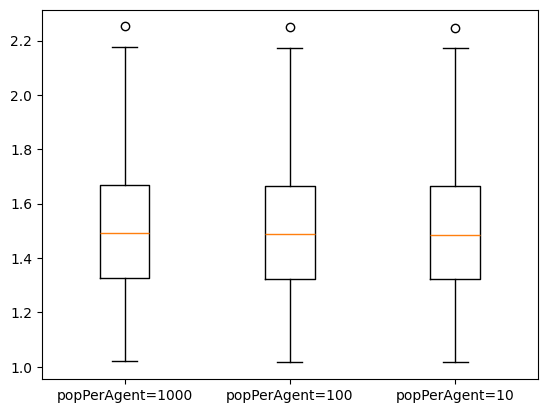

In [39]:
data, labels = [], []
for k in numAgents:
    data.append(merged_popPerAgent[f'popPerAgent={k}'])
    labels.append(f'popPerAgent={k}')
plt.boxplot(data, tick_labels=labels)
plt.show()

/tmp/ipykernel_1935603/1349747492.py:9: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  w = Queen.from_dataframe(merged_popPerAgent)


-1.7744282426446651 1.7550139114096661
1000: Moran's I: 0.8570118861721616, p-value: 0.001
-0.6758723982756963 1.495617087598401
100: Moran's I: 0.6739569258172685, p-value: 0.001


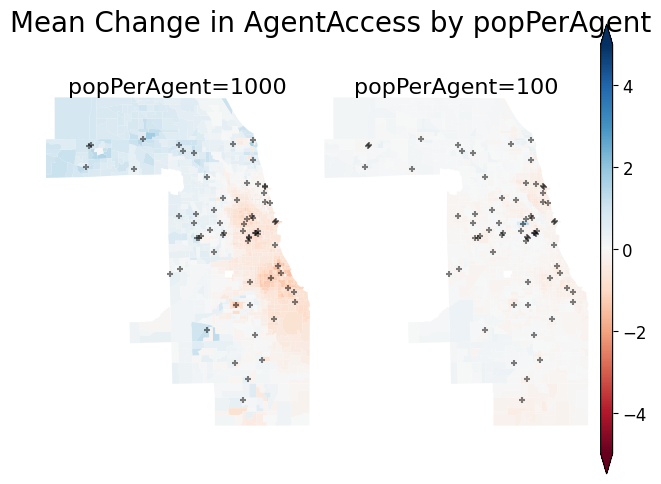

In [40]:
fontsize = 16
mycmap="RdBu"
hosmarkersize = 25
vmin, vmax = -5, 5

fig, axes = plt.subplots(1, 2, figsize=(6, 5))
fig.subplots_adjust(wspace=0, hspace=.1)

w = Queen.from_dataframe(merged_popPerAgent)
w.transform = 'R'

for ind, (k, ax) in enumerate(zip(numAgents[0:2], axes.flatten())):
    merged_popPerAgent[f"diff_{k}"] = 100 *(merged_popPerAgent['popPerAgent=10'] - merged_popPerAgent[f'popPerAgent={k}']) / ((merged_popPerAgent['popPerAgent=10'] + merged_popPerAgent[f'popPerAgent={k}']) / 2.0)
    print(np.min(merged_popPerAgent[f"diff_{k}"]),np.max(merged_popPerAgent[f"diff_{k}"]))
    moran = Moran(merged_popPerAgent[f"diff_{k}"], w)
    print(f"{k}: Moran's I: {moran.I}, p-value: {moran.p_sim}")
    ax.set_title(f"popPerAgent={k}", fontsize=fontsize, pad=0)
    merged_popPerAgent.plot(ax=ax, column=f"diff_{k}", cmap=mycmap, vmin=vmin, vmax=vmax)
    ax.axis('off')
    ax.margins(0)
    hos.plot(ax=ax, alpha=.5, color='black', marker='+', markersize=hosmarkersize)
plt.tight_layout()


normalizer = Normalize(vmin, vmax)
im = cm.ScalarMappable(cmap=mycmap, norm=normalizer)
fig.subplots_adjust(right=0.93)
# recttuple (left, bottom, width, height)
cbar_ax = fig.add_axes([0.95, 0.05, 0.02, 0.9])

cbar_ax.tick_params(labelsize=fontsize-4)
fig.colorbar(im, cax=cbar_ax, extend='both')

fig.subplots_adjust(top=0.92)
fig.suptitle(f"Mean Change in AgentAccess by popPerAgent", fontsize=fontsize+4)

# plt.tight_layout()
plt.savefig(f"../figs/ComparisonBypopPerAgent-Againstppa1-Logit.png", dpi=400, bbox_inches='tight', pad_inches=0)
plt.show()